# Phishing Website Detection — Logistic Regression from scratch (complete implementation)

**7th-semester Computer Engineering · Machine Learning PBL**

This notebook is **self-contained**: every step — loading, cleaning, splitting, encoding, the Logistic Regression
model, training, threshold tuning, evaluation, bootstrap confidence intervals, cross-validation, feature selection,
interpretation and the app's 8-input model — is **implemented in the cells below**, not imported from the project's
`src/` package. The same code lives in `src/*.py` for the pipeline and the app; the last part checks that the
notebook's models are identical to the saved ones.

| # | Part |
|---|---|
| 0 | Setup and constants |
| 1 | Problem |
| 2 | Dataset: load, audit duplicates, clean, map labels, split |
| 3 | Visualization (training data only) |
| 4 | Preprocessing: input validation, one-hot encoder, baselines |
| 5 | Logistic Regression from scratch: maths, code, gradient check, tuning, threshold |
| 6 | Results and evaluation: metrics, cross-validation, test set, bootstrap intervals |
| 7 | Overfitting and underfitting; feature selection |
| 8 | Interpretation: coefficients, permutation importance |
| 9 | The app's 8-input model: verdict zones and "why this result?" |
| 10 | Verification against the saved models |
| 11 | Conclusion |

**Allowed library use.** NumPy and pandas for the implementation; scikit-learn only for metric formulas
(`roc_auc_score` etc.), fold indices, mutual information and a *separate* reference model.

## 0. Setup and constants

In [1]:
import json, time, inspect
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss, confusion_matrix, f1_score,
                             log_loss, mutual_info_score, precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression as SkLogisticRegression   # reference model only

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DATA_PATH = ROOT / "data" / "raw" / "phishing.csv"
MODELS_DIR = ROOT / "models"

RANDOM_SEED = 42
TARGET_COLUMN = "result"          # original label column in the UCI file
TARGET = "phishing"               # project label: 1 = phishing, 0 = legitimate
LABEL_MAPPING = {-1: 1, 1: 0}     # original -1 (phishing) -> 1, +1 (legitimate) -> 0
PHISH, LEGIT = "#e2643a", "#2a78d6"

RUN_GRID = False   # True re-runs the 30-fit hyperparameter search in Part 5 (about 10 minutes)
print("project root:", ROOT)

project root: C:\Users\Asus\OneDrive\Desktop\mlproject2


## 1. Problem

Phishing websites copy trusted brands to steal passwords and card details. Each website in the UCI *Phishing
Websites* dataset is described by **30 pre-extracted indicators** coded −1, 0 or 1 (for example *is the HTTPS
certificate valid?*, *does the domain contain a dash?*).

* **Task:** binary classification — estimate $P(\text{phishing} \mid x)$ and decide with a threshold.
* **Positive class:** phishing = 1, legitimate = 0.
* **Model:** logistic regression written from scratch.

## 2. Dataset

**Source:** UCI Machine Learning Repository, *Phishing Websites* (id 327), Mohammad, Thabtah & McCluskey (2012),
licence CC BY 4.0. A local copy is stored in `data/raw/phishing.csv`.

In [2]:
def load_raw(path: Path = RAW_DATA_PATH) -> pd.DataFrame:
    """Read the saved UCI file and check that the label column is there."""
    if not path.exists():
        raise FileNotFoundError(f"{path} not found — download the UCI dataset first")
    df = pd.read_csv(path)
    if TARGET_COLUMN not in df.columns:
        raise ValueError(f"target column '{TARGET_COLUMN}' missing")
    return df


raw = load_raw()
print("shape:", raw.shape, "| missing values:", int(raw.isna().sum().sum()))
print("label values:", raw[TARGET_COLUMN].value_counts().to_dict())
values = {c: sorted(raw[c].unique().tolist()) for c in raw.columns if c != TARGET_COLUMN}
print("value sets:", pd.Series({c: str(v) for c, v in values.items()}).value_counts().to_dict())
raw.head()

shape: (11055, 31) | missing values: 0
label values: {1: 6157, -1: 4898}
value sets: {'[-1, 1]': 21, '[-1, 0, 1]': 8, '[0, 1]': 1}


,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,...,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report,result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


### 2.1 Duplicate audit and cleaning

With only 30 coarse indicators, many websites collapse to the same row. If identical rows sit in both the training
and the test data, the test score rewards memorising. The cleaning rule (decided in the inspection phase):

1. collapse exact duplicates (same features **and** label) to one row;
2. drop every feature vector that appears with **both** labels — no label is guessed;
3. only then split.

In [3]:
def feature_columns(df: pd.DataFrame) -> list[str]:
    """Predictor columns in file order (everything except the label columns)."""
    return [c for c in df.columns if c not in (TARGET_COLUMN, TARGET)]


def map_labels(df: pd.DataFrame) -> pd.DataFrame:
    """Replace result (-1/+1) by phishing (1/0); refuse unknown labels."""
    unknown = set(df[TARGET_COLUMN].unique()) - set(LABEL_MAPPING)
    if unknown:
        raise ValueError(f"unexpected target values: {sorted(unknown)}")
    out = df.drop(columns=TARGET_COLUMN)
    out[TARGET] = df[TARGET_COLUMN].map(LABEL_MAPPING).astype(int)
    return out


def clean(df: pd.DataFrame) -> pd.DataFrame:
    """Apply the duplicate policy, then map labels. Row order follows first occurrence."""
    features = feature_columns(df)
    unique = df.drop_duplicates(keep="first")
    labels_per_vector = unique.groupby(features, sort=False)[TARGET_COLUMN].transform("nunique")
    kept = unique[labels_per_vector.values == 1]          # vectors seen with both labels are dropped
    return map_labels(kept).reset_index(drop=True)


FEATS = feature_columns(raw)
unique_rows = raw.drop_duplicates()
conflicting = int((unique_rows.groupby(FEATS)[TARGET_COLUMN].nunique() > 1).sum())
cleaned = clean(raw)
print(f"exact duplicate rows : {raw.duplicated().sum():,} ({raw.duplicated().mean():.1%})")
print(f"conflicting vectors  : {conflicting}")
pd.DataFrame({"rows": [len(raw), len(unique_rows), len(cleaned)],
              "phishing share": [f"{(raw[TARGET_COLUMN] == -1).mean():.1%}", f"{(unique_rows[TARGET_COLUMN] == -1).mean():.1%}",
                                 f"{cleaned[TARGET].mean():.1%}"]},
             index=["original", "exact duplicates removed", "conflicting vectors removed"])

exact duplicate rows : 5,206 (47.1%)
conflicting vectors  : 64


,rows,phishing share
original,11055,44.3%
exact duplicates removed,5849,51.6%
conflicting vectors removed,5721,51.7%


### 2.2 Stratified 70 / 15 / 15 split (seed 42)

The test set is carved off first, then the rest is split into training and validation. Stratification keeps the
phishing rate equal in all three parts. **Training** fits the parameters, **validation** chooses settings, and
**test** is used once at the very end.

In [4]:
def split_indices(y, train_size: float = 0.70, val_size: float = 0.15, seed: int = RANDOM_SEED):
    """Row positions of the train / validation / test partitions (stratified, reproducible)."""
    y = np.asarray(y)
    idx = np.arange(len(y))
    test_size = round(1.0 - train_size - val_size, 10)   # 1 - 0.70 - 0.15 is 0.15000000000000002 in floating point
    rest, test = train_test_split(idx, test_size=test_size, stratify=y, random_state=seed)
    train, val = train_test_split(rest, test_size=val_size / (train_size + val_size), stratify=y[rest],
                                  random_state=seed)
    return np.sort(train), np.sort(val), np.sort(test)


tr_idx, va_idx, te_idx = split_indices(cleaned[TARGET])
train, val, test = cleaned.iloc[tr_idx], cleaned.iloc[va_idx], cleaned.iloc[te_idx]
ytr, yva, yte = (d[TARGET].to_numpy() for d in (train, val, test))

key = lambda df: set(map(tuple, df[FEATS].to_numpy()))
print("feature vectors shared train/test:", len(key(train) & key(test)), "| train/val:", len(key(train) & key(val)))
pd.DataFrame({"rows": [len(train), len(val), len(test)],
              "phishing rate": [ytr.mean().round(4), yva.mean().round(4), yte.mean().round(4)]},
             index=["train", "validation", "test"])

feature vectors shared train/test: 0 | train/val: 0


,rows,phishing rate
train,4004,0.5165
validation,858,0.5163
test,859,0.5169


## 3. Visualization of the dataset

Label statistics use the **training split only**.

### 3.1 Class balance before and after cleaning

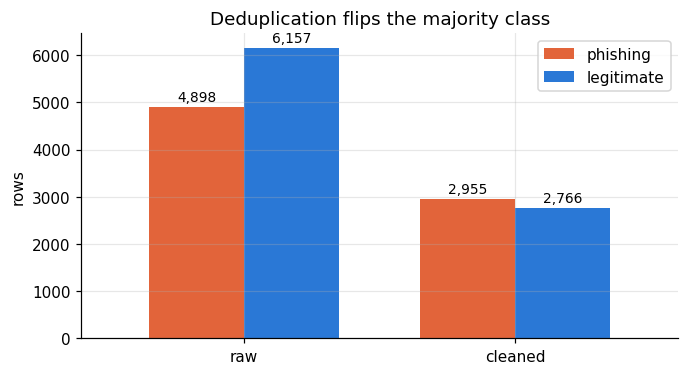

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.6))
counts = pd.DataFrame({"raw": [(raw[TARGET_COLUMN] == -1).sum(), (raw[TARGET_COLUMN] == 1).sum()],
                       "cleaned": [cleaned[TARGET].sum(), (cleaned[TARGET] == 0).sum()]},
                      index=["phishing", "legitimate"])
counts.T.plot.bar(ax=ax, color=[PHISH, LEGIT], rot=0, width=0.7)
for c in ax.containers:
    ax.bar_label(c, fmt="{:,.0f}", padding=2, fontsize=9)
ax.set_ylabel("rows"); ax.set_title("Deduplication flips the majority class")
plt.show()

**What it shows.** The HTTPS certificate (`sslfinal_state`) and anchor-link targets (`url_of_anchor`) separate the
classes most strongly. Several features are **not ordered**: certificate code 0 (HTTPS from an untrusted issuer) is
*riskier* than code −1. A linear model given the raw −1/0/1 numbers would wrongly assume equal steps, so we will
one-hot encode. These are associations, not causes.

### 3.3 How good is each feature on its own?

A one-feature "model" scores a site by the (smoothed) training phishing rate of its code. It doubles as the
**best-single-feature baseline**.

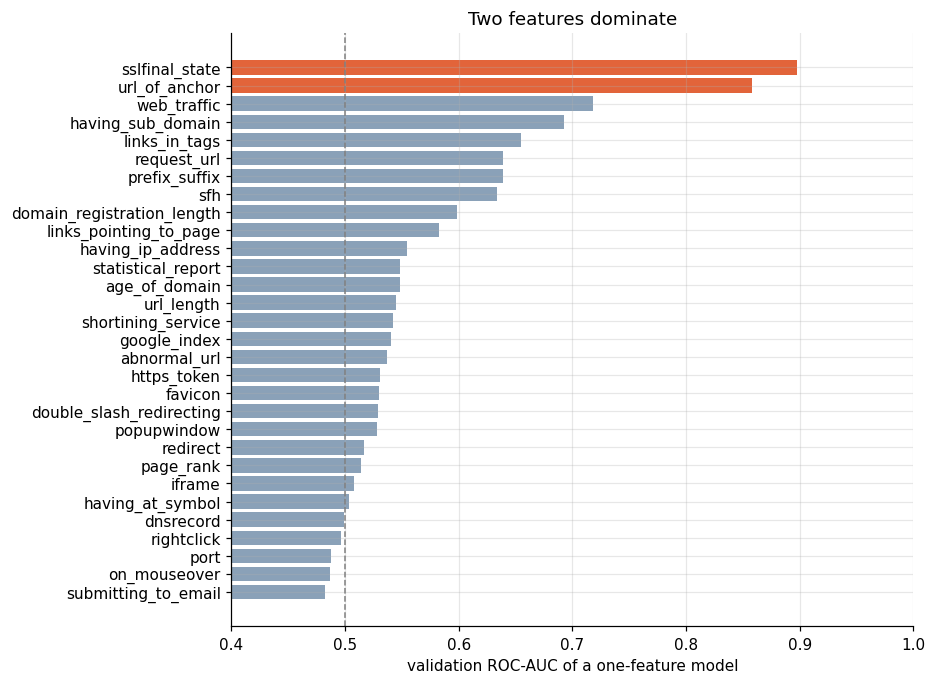

best single feature: sslfinal_state 0.898 — strong but far from 1, so no label leakage


In [7]:
class MajorityBaseline:
    """Probability = training phishing rate for every row."""
    def fit(self, X, y):
        self.prior_ = float(np.mean(y)); return self
    def predict_proba(self, X):
        return np.full(len(X), self.prior_)


class SingleFeatureBaseline:
    """Laplace-smoothed training phishing rate of one feature's code."""
    def __init__(self, feature_index: int, alpha: float = 1.0):
        self.feature_index, self.alpha = feature_index, alpha
    def fit(self, X, y):
        x = X[:, self.feature_index]
        self.prior_ = float(np.mean(y))
        self.rates_ = {float(v): (y[x == v].sum() + self.alpha * self.prior_) / ((x == v).sum() + self.alpha)
                       for v in np.unique(x)}
        return self
    def predict_proba(self, X):
        return np.array([self.rates_.get(float(v), self.prior_) for v in X[:, self.feature_index]])


Xtr_raw, Xva_raw, Xte_raw = (d[FEATS].to_numpy(float) for d in (train, val, test))
single = pd.Series({f: roc_auc_score(yva, SingleFeatureBaseline(j).fit(Xtr_raw, ytr).predict_proba(Xva_raw))
                    for j, f in enumerate(FEATS)}).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(single.index, single.values, color=[PHISH if v > 0.8 else "#8aa1b8" for v in single.values])
ax.axvline(0.5, color="grey", lw=1, ls="--"); ax.set_xlim(0.4, 1)
ax.set_xlabel("validation ROC-AUC of a one-feature model"); ax.set_title("Two features dominate")
plt.show()
best_feat = single.idxmax()
print("best single feature:", best_feat, round(single.max(), 3), "— strong but far from 1, so no label leakage")

## 4. Preprocessing

* **Missing values:** none in the data — but every input is still validated.
* **Scaling:** not needed — all inputs are bounded codes, and one-hot columns are 0/1.
* **Encoding:** one-hot. For each feature, every level except the highest code (1, the legitimate-like level) gets
  its own 0/1 column; code 1 is the **reference level**. The encoder is fitted on training data only.

In [8]:
def validate_features(df: pd.DataFrame, levels: dict[str, list[int]]) -> list[str]:
    """Human-readable problems: missing columns, missing / non-numeric values, codes never seen in training."""
    problems = []
    missing = [f for f in levels if f not in df.columns]
    if missing:
        problems.append(f"missing columns: {missing}")
    for f, allowed in levels.items():
        if f not in df.columns:
            continue
        col = pd.to_numeric(df[f], errors="coerce")
        if col.isna().any():
            problems.append(f"{f}: {int(col.isna().sum())} missing or non-numeric value(s)")
        bad = sorted(set(col.dropna().unique()) - set(allowed))
        if bad:
            problems.append(f"{f}: invalid value(s) {bad}; allowed {allowed}")
    return problems


class FeatureEncoder:
    """Turns a frame of coded features into a numeric matrix in a fixed column order ('raw' or 'onehot')."""

    def __init__(self, kind: str = "onehot"):
        if kind not in ("raw", "onehot"):
            raise ValueError("kind must be 'raw' or 'onehot'")
        self.kind, self.features, self.levels = kind, [], {}

    def fit(self, df: pd.DataFrame) -> "FeatureEncoder":
        self.features = feature_columns(df)
        self.levels = {f: sorted(int(v) for v in df[f].unique()) for f in self.features}
        return self

    @property
    def output_names(self) -> list[str]:
        if self.kind == "raw":
            return list(self.features)
        return [f"{f}={v}" for f in self.features for v in self.levels[f][:-1]]   # last level = reference

    def transform(self, df: pd.DataFrame) -> np.ndarray:
        problems = validate_features(df, self.levels)
        if problems:
            raise ValueError("invalid input: " + "; ".join(problems))
        X = df[self.features].to_numpy(dtype=float)
        if self.kind == "raw":
            return X
        return np.column_stack([(X[:, j] == v) for j, f in enumerate(self.features)
                                for v in self.levels[f][:-1]]).astype(float)


enc = FeatureEncoder("onehot").fit(train)
enc_raw = FeatureEncoder("raw").fit(train)
Xtr, Xva, Xte = (enc.transform(d) for d in (train, val, test))
print("30 features ->", Xtr.shape[1], "one-hot inputs, e.g.", enc.output_names[:5])

bad = train[FEATS].head(3).copy().astype(object)
bad.iloc[0, 0] = 7; bad.iloc[1, 3] = None
print("validation demo:", validate_features(bad.drop(columns=["url_length"]), enc.levels))

30 features -> 38 one-hot inputs, e.g. ['having_ip_address=-1', 'url_length=-1', 'url_length=0', 'shortining_service=-1', 'having_at_symbol=-1']
validation demo: ["missing columns: ['url_length']", 'having_ip_address: invalid value(s) [np.int64(7)]; allowed [-1, 1]', 'having_at_symbol: 1 missing or non-numeric value(s)']


### 4.1 Metrics and baselines

All metrics treat **phishing as the positive class**. Ranking metrics (ROC-AUC, PR-AUC) and log-loss use the
probabilities; the others use `probability ≥ threshold`.

In [9]:
def compute_metrics(y, proba, threshold: float = 0.5) -> dict:
    """Threshold metrics, ranking metrics, log-loss (probabilities clipped to [1e-6, 1-1e-6]) and confusion counts."""
    y, proba = np.asarray(y).astype(int), np.asarray(proba, dtype=float)
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    return {"threshold": float(threshold), "accuracy": accuracy_score(y, pred),
            "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred, zero_division=0),
            "f1": f1_score(y, pred, zero_division=0), "macro_f1": f1_score(y, pred, average="macro", zero_division=0),
            "roc_auc": roc_auc_score(y, proba) if both else np.nan,
            "pr_auc": average_precision_score(y, proba) if both else np.nan,
            "log_loss": log_loss(y, np.clip(proba, 1e-6, 1 - 1e-6), labels=[0, 1]),
            "brier": brier_score_loss(y, proba), "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}


def metrics_row(y, p, thr):
    m = compute_metrics(y, p, thr)
    return {k: round(float(m[k]), 3) for k in ("threshold", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc")}


def sklearn_logistic(l2: float, n_train: int) -> SkLogisticRegression:
    """REFERENCE model with the same objective: sklearn minimises C·ΣBCE + ½‖w‖², so C = 1 / (λ·n)."""
    if l2 == 0:
        return SkLogisticRegression(penalty=None, max_iter=5000, random_state=RANDOM_SEED)
    return SkLogisticRegression(C=1.0 / (l2 * n_train), max_iter=5000, random_state=RANDOM_SEED)


base = {"Majority class": MajorityBaseline().fit(Xtr_raw, ytr).predict_proba(Xva_raw),
        f"Best single feature ({best_feat})": SingleFeatureBaseline(FEATS.index(best_feat)).fit(Xtr_raw, ytr).predict_proba(Xva_raw),
        "sklearn LR reference (one-hot)": sklearn_logistic(0.0, len(ytr)).fit(Xtr, ytr).predict_proba(Xva)[:, 1]}
pd.DataFrame({k: metrics_row(yva, p, 0.5) for k, p in base.items()}).T

,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
Majority class,0.5,0.516,0.516,1.000,0.681,0.500,0.516
Best single feature (sslfinal_state),0.5,0.888,0.914,0.865,0.889,0.898,0.877
sklearn LR reference (one-hot),0.5,0.945,0.952,0.941,0.947,0.988,0.990


Accuracy alone is misleading: the majority baseline answers *phishing* for everything — recall 1.0 and accuracy 0.52 with zero skill.

## 5. Logistic Regression from scratch

### 5.1 The maths

$$z = w^\top x + b, \qquad p = \sigma(z) = \frac{1}{1 + e^{-z}}$$

Binary cross-entropy for one row, written in a numerically safe form:

$$\ell = -\big[y \log p + (1-y)\log(1-p)\big] = \log(1 + e^{z}) - y\,z$$

Objective with L2 regularisation (the bias $b$ is not penalised) and optional sample weights $s_i$:

$$J(w,b) = \frac{\sum_i s_i \ell_i}{\sum_i s_i} + \frac{\lambda}{2}\lVert w\rVert^2$$

Gradient — from $\partial\ell/\partial p = \frac{p-y}{p(1-p)}$, $\partial p/\partial z = p(1-p)$ and
$\partial z/\partial w = x$:

$$\nabla_w J = \frac{X^\top\!\big(s \odot (p - y)\big)}{\sum s} + \lambda w, \qquad
\frac{\partial J}{\partial b} = \frac{\sum_i s_i (p_i - y_i)}{\sum s}$$

Gradient descent repeats $w \leftarrow w - \eta \nabla_w J$. The loss is convex and $L$-smooth with
$L = \tfrac14 \lambda_{\max}(\tilde X^\top \tilde X / n) + \lambda$, so any step $\eta < 2/L$ is guaranteed to
decrease it.

### 5.2 The implementation

In [ ]:
def sigmoid(z: np.ndarray) -> np.ndarray:
    """Numerically stable logistic function: exp() never receives a large positive argument."""
    z = np.asarray(z, dtype=float)
    out = np.empty_like(z)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out


def _check_X(X, n_features=None) -> np.ndarray:
    X = np.asarray(X, dtype=float)
    if X.ndim != 2:
        raise ValueError(f"X must be 2-D, got shape {X.shape}")
    if not np.isfinite(X).all():
        raise ValueError("X contains NaN or infinite values")
    if n_features is not None and X.shape[1] != n_features:
        raise ValueError(f"X has {X.shape[1]} features, model expects {n_features}")
    return X


def _check_y(y, n: int) -> np.ndarray:
    y = np.asarray(y)
    if y.ndim != 1 or len(y) != n:
        raise ValueError("y must be 1-D with one label per row of X")
    if not np.isin(y, (0, 1)).all():
        raise ValueError("y must contain only 0 and 1")
    return y.astype(float)


class LogisticRegression:
    def __init__(self, learning_rate=0.5, n_iter=5000, l2=0.0, batch_size=None, class_weight=None, tol=1e-8, seed=42):
        if learning_rate <= 0 or n_iter < 1 or l2 < 0:
            raise ValueError("learning_rate and n_iter must be positive, l2 non-negative")
        self.learning_rate, self.n_iter, self.l2 = learning_rate, n_iter, l2
        self.batch_size, self.class_weight, self.tol, self.seed = batch_size, class_weight, tol, seed
        self.w, self.b = None, 0.0
        self.history = {"train_loss": [], "val_loss": []}
        self.n_iter_run, self.converged = 0, False

    def _sample_weights(self, y):
        if self.class_weight is None:
            return np.ones_like(y)
        if self.class_weight == "balanced":                 # s_i = n / (2 · n_class)
            n, n1 = len(y), y.sum()
            cw = {0: n / (2 * (n - n1)), 1: n / (2 * n1)}
        else:
            cw = {int(k): float(v) for k, v in self.class_weight.items()}
        return np.where(y == 1, cw[1], cw[0])

    def objective(self, X, y, w, b, s=None) -> float:
        z = X @ w + b
        s = np.ones_like(y) if s is None else s
        bce = np.logaddexp(0.0, z) - y * z                   # log(1 + e^z) − y·z, never log(0)
        return float(np.dot(s, bce) / s.sum() + 0.5 * self.l2 * np.dot(w, w))

    def gradient(self, X, y, w, b, s=None):
        """(∂J/∂w, ∂J/∂b)."""
        s = np.ones_like(y) if s is None else s
        r = s * (sigmoid(X @ w + b) - y) / s.sum()           # weighted residuals p − y
        return X.T @ r + self.l2 * w, float(r.sum())

    # ---- training
    def fit(self, X, y, X_val=None, y_val=None) -> "LogisticRegression":
        X = _check_X(X)
        y = _check_y(y, len(X))
        if len(np.unique(y)) < 2:
            raise ValueError("training data must contain both classes")
        has_val = X_val is not None and y_val is not None
        if has_val:
            X_val, y_val = _check_X(X_val, X.shape[1]), _check_y(y_val, len(X_val))
        s = self._sample_weights(y)
        w, b = np.zeros(X.shape[1]), 0.0
        rng = np.random.default_rng(self.seed)
        self.history, self.converged = {"train_loss": [], "val_loss": []}, False
        s_sum, prev = s.sum(), np.inf
        for it in range(1, self.n_iter + 1):
            #full-batch
            if self.batch_size is None:
                # one pass: logits -> loss at the current parameters -> gradient -> step
                z = X @ w + b
                cur = float(np.dot(s, np.logaddexp(0.0, z) - y * z) / s_sum + 0.5 * self.l2 * np.dot(w, w))
                r = s * (sigmoid(z) - y) / s_sum
                w, b = w - self.learning_rate * (X.T @ r + self.l2 * w), b - self.learning_rate * float(r.sum())
            #mini-batch    
            else:
                order = rng.permutation(len(X))
                for start in range(0, len(X), self.batch_size):
                    idx = order[start:start + self.batch_size]
                    gw, gb = self.gradient(X[idx], y[idx], w, b, s[idx])
                    w, b = w - self.learning_rate * gw, b - self.learning_rate * gb
                cur = self.objective(X, y, w, b, s)
            if not np.isfinite(cur):
                raise FloatingPointError("objective diverged; reduce learning_rate")
            self.history["train_loss"].append(cur)
            if has_val:
                zv = X_val @ w + b
                self.history["val_loss"].append(float(np.mean(np.logaddexp(0.0, zv) - y_val * zv)))
            self.n_iter_run = it
            if self.batch_size is None and abs(prev - cur) < self.tol:
                self.converged = True
                break
            prev = cur
        self.w, self.b = w, b
        return self

    # ---- inference
    def decision_function(self, X) -> np.ndarray:
        if self.w is None:
            raise RuntimeError("model is not fitted")
        return _check_X(X, len(self.w)) @ self.w + self.b

    def predict_proba(self, X) -> np.ndarray:
        return sigmoid(self.decision_function(X))

    def predict(self, X, threshold: float = 0.5) -> np.ndarray:
        if not 0.0 <= threshold <= 1.0:
            raise ValueError("threshold must be in [0, 1]")
        return (self.predict_proba(X) >= threshold).astype(int)

    # ---- persistence (same JSON format as models/*.json)
    def to_dict(self) -> dict:
        return {"model": "LogisticRegression (custom, NumPy)",
                "params": {"learning_rate": self.learning_rate, "n_iter": self.n_iter, "l2": self.l2,
                           "batch_size": self.batch_size, "class_weight": self.class_weight, "tol": self.tol,
                           "seed": self.seed},
                "weights": self.w.tolist(), "bias": self.b, "n_iter_run": self.n_iter_run, "converged": self.converged}

    @classmethod
    def from_dict(cls, d: dict) -> "LogisticRegression":
        m = cls(**d["params"])
        m.w, m.b = np.asarray(d["weights"], dtype=float), float(d["bias"])
        m.n_iter_run, m.converged = d.get("n_iter_run", 0), d.get("converged", False)
        return m

### 5.3 Gradient check

The analytic gradient must agree with a finite-difference estimate $\frac{J(w+\epsilon e_k) - J(w-\epsilon e_k)}{2\epsilon}$.

In [11]:
rng = np.random.default_rng(0)
Xs, ys = rng.normal(size=(50, 4)), rng.integers(0, 2, 50).astype(float)
m = LogisticRegression(l2=0.1)
w0, b0, eps = rng.normal(size=4), 0.3, 1e-6
gw, gb = m.gradient(Xs, ys, w0, b0)
num = np.array([(m.objective(Xs, ys, w0 + eps * e, b0) - m.objective(Xs, ys, w0 - eps * e, b0)) / (2 * eps) for e in np.eye(4)])
num_b = (m.objective(Xs, ys, w0, b0 + eps) - m.objective(Xs, ys, w0, b0 - eps)) / (2 * eps)
print("analytic ∂J/∂w :", gw.round(6)); print("numerical ∂J/∂w:", num.round(6))
print("max |difference| (w):", float(np.abs(gw - num).max()), "| (b):", abs(gb - num_b))

analytic ∂J/∂w : [ 0.199916 -0.128656  0.434444  0.320001]
numerical ∂J/∂w: [ 0.199916 -0.128656  0.434444  0.320001]
max |difference| (w): 1.6658241452915945e-10 | (b): 6.755753248488539e-11


### 5.4 Choosing the settings (validation data only)

The grid is encoding {raw, one-hot} × λ {0, 1e-4, 1e-3, 1e-2, 1e-1} × learning rate {0.5, 1, 1.9}/L, with up to
30,000 iterations. The winner is the lowest **validation log-loss** (a proper scoring rule, because the app shows
probabilities); ties go to the larger λ, then the smaller step. Set `RUN_GRID = True` in Part 0 to re-run all 30 fits
here (≈ 10 minutes); otherwise the notebook uses the setting that this search selects.

In [12]:
encoders = {"raw": enc_raw, "onehot": enc}
mats = {k: {p: e.transform(d) for p, d in (("train", train), ("val", val), ("test", test))} for k, e in encoders.items()}


def grid_search():
    rows = []
    for kind in ("raw", "onehot"):
        Xa, Xb = mats[kind]["train"], mats[kind]["val"]
        L = LogisticRegression.smoothness_constant(Xa)
        for l2 in (0.0, 1e-4, 1e-3, 1e-2, 1e-1):
            for frac in (0.5, 1.0, 1.9):
                lr_ = round(frac / L, 4)
                mdl = LogisticRegression(learning_rate=lr_, l2=l2, n_iter=30000, tol=1e-9).fit(Xa, ytr)
                rows.append({"encoding": kind, "l2": l2, "lr_times_L": frac, "learning_rate": lr_,
                             "iterations": mdl.n_iter_run,
                             "train_log_loss": compute_metrics(ytr, mdl.predict_proba(Xa))["log_loss"],
                             "val_log_loss": compute_metrics(yva, mdl.predict_proba(Xb))["log_loss"]})
    return pd.DataFrame(rows)


if RUN_GRID:
    grid = grid_search()
    best = grid.assign(r=grid.val_log_loss.round(4)).sort_values(["r", "l2", "learning_rate"],
                                                                 ascending=[True, False, True]).iloc[0]
    print(grid.pivot_table(index=["encoding", "l2"], columns="lr_times_L", values="val_log_loss").round(4))
    SEL = {"encoding": best.encoding, "l2": float(best.l2), "lr_times_L": float(best.lr_times_L)}
else:
    SEL = {"encoding": "onehot", "l2": 1e-4, "lr_times_L": 1.0}   # the setting the grid selects
L = LogisticRegression.smoothness_constant(mats[SEL["encoding"]]["train"])
SEL["learning_rate"] = round(SEL["lr_times_L"] / L, 4)
print("selected:", SEL, f"| L = {L:.3f}, stable for steps below 2/L = {2 / L:.3f}")

selected: {'encoding': 'onehot', 'l2': 0.0001, 'lr_times_L': 1.0, 'learning_rate': 0.5464} | L = 1.830, stable for steps below 2/L = 1.093


### 5.5 Training the selected model

trained in 14.3s · 27,079 iterations · converged = True


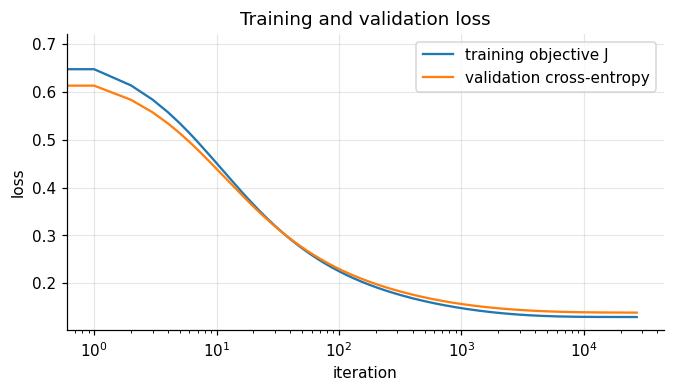

In [13]:
t0 = time.perf_counter()
lr = LogisticRegression(learning_rate=SEL["learning_rate"], l2=SEL["l2"], n_iter=30000, tol=1e-9).fit(Xtr, ytr, Xva, yva)
print(f"trained in {time.perf_counter() - t0:.1f}s · {lr.n_iter_run:,} iterations · converged = {lr.converged}")

h = lr.history
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(h["train_loss"], label="training objective J"); ax.plot(h["val_loss"], label="validation cross-entropy")
ax.set_xscale("log"); ax.set(xlabel="iteration", ylabel="loss", title="Training and validation loss")
ax.legend(); plt.show()

**Why so many iterations?** Some one-hot levels almost perfectly separate the classes (e.g. `prefix_suffix = 1` is never
phishing), so the optimum has large weights that plain gradient descent approaches slowly.

### 5.6 Learning rate: below and above the 2/L bound

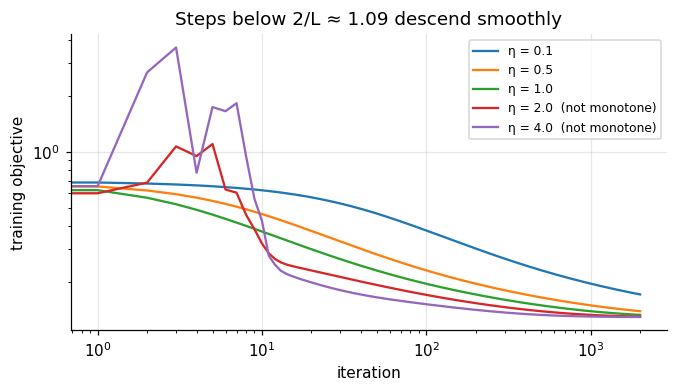

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for rate in (0.1, 0.5, 1.0, 2.0, 4.0):
    m = LogisticRegression(learning_rate=rate, l2=SEL["l2"], n_iter=2000, tol=0).fit(Xtr, ytr)
    hist = np.array(m.history["train_loss"])
    ax.plot(hist, label=f"η = {rate}" + ("" if np.all(np.diff(hist) <= 1e-12) else "  (not monotone)"))
ax.set(xscale="log", yscale="log", xlabel="iteration", ylabel="training objective",
       title=f"Steps below 2/L ≈ {2 / L:.2f} descend smoothly")
ax.legend(fontsize=8); plt.show()

### 5.7 Decision threshold (validation data only)

The model outputs a probability; we flag phishing when it is at least a threshold. The threshold is the one that
maximises validation F1 (ties go to the value nearest 0.5).

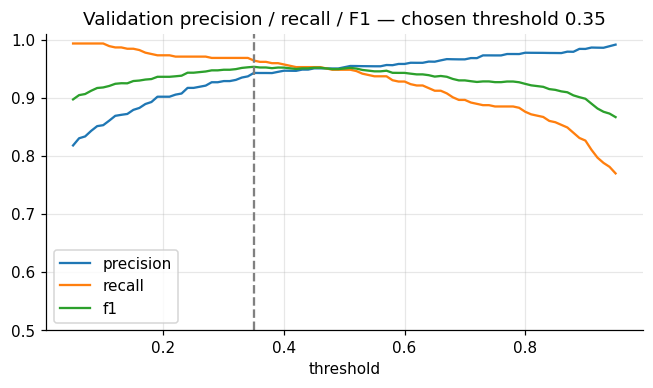

max |weight difference| vs scikit-learn reference: 0.069 | max |probability difference|: 0.016


,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
custom LR,0.35,0.951,0.943,0.964,0.953,0.988,0.989
sklearn LR (reference),0.35,0.949,0.940,0.962,0.951,0.988,0.989
custom LR — training data,0.35,0.950,0.939,0.966,0.952,0.991,0.992


In [15]:
def threshold_curve(y, proba, grid=None) -> dict:
    grid = np.round(np.linspace(0.05, 0.95, 91), 3) if grid is None else grid
    rows = [compute_metrics(y, proba, t) for t in grid]
    return {"threshold": grid, **{k: [r[k] for r in rows] for k in ("precision", "recall", "f1")}}


def tune_threshold(y, proba, objective: str = "f1") -> float:
    grid = np.round(np.linspace(0.05, 0.95, 91), 3)
    vals = np.array([compute_metrics(y, proba, t)[objective] for t in grid])
    best = np.flatnonzero(np.isclose(vals, vals.max()))
    return float(grid[best[np.argmin(np.abs(grid[best] - 0.5))]])


p_val = lr.predict_proba(Xva)
THR = tune_threshold(yva, p_val)
curve = threshold_curve(yva, p_val)
fig, ax = plt.subplots(figsize=(7, 3.5))
for k in ("precision", "recall", "f1"):
    ax.plot(curve["threshold"], curve[k], label=k)
ax.axvline(THR, color="grey", ls="--"); ax.set(xlabel="threshold", ylim=(0.5, 1.01),
                                              title=f"Validation precision / recall / F1 — chosen threshold {THR:.2f}")
ax.legend(); plt.show()

sk = sklearn_logistic(SEL["l2"], len(ytr)).fit(Xtr, ytr)
p_sk_val = sk.predict_proba(Xva)[:, 1]
print("max |weight difference| vs scikit-learn reference:", round(float(np.abs(sk.coef_[0] - lr.w).max()), 3),
      "| max |probability difference|:", round(float(np.abs(p_sk_val - p_val).max()), 3))
pd.DataFrame({"custom LR": metrics_row(yva, p_val, THR), "sklearn LR (reference)": metrics_row(yva, p_sk_val, THR),
              "custom LR — training data": metrics_row(ytr, lr.predict_proba(Xtr), THR)}).T

## 6. Results and evaluation

### 6.1 Stratified 5-fold cross-validation (training split only)

The training split is cut into 5 folds with equal phishing rates; the model is fitted on 4 and scored on the 5th,
five times. This shows how much the scores vary. Validation and test are not touched.

In [16]:
def stratified_folds(y, k: int = 5, seed: int = RANDOM_SEED):
    """k (fit_idx, held_out_idx) pairs — scikit-learn generates only the indices."""
    return list(StratifiedKFold(n_splits=k, shuffle=True, random_state=seed).split(np.zeros(len(y)), y))


def cross_validate(fit_predict, X, y, folds, threshold):
    out = {m: [] for m in ("roc_auc", "f1", "log_loss")}
    for fit_idx, held_idx in folds:
        mtr = compute_metrics(y[held_idx], fit_predict(X[fit_idx], y[fit_idx], X[held_idx]), threshold)
        for k in out:
            out[k].append(mtr[k])
    return out


folds = stratified_folds(ytr)
cv = {
    "Custom LR": cross_validate(lambda a, b, c: LogisticRegression(learning_rate=SEL["learning_rate"], l2=SEL["l2"],
                                n_iter=30000, tol=1e-9).fit(a, b).predict_proba(c), Xtr, ytr, folds, THR),
    "Best single feature": cross_validate(lambda a, b, c: SingleFeatureBaseline(FEATS.index(best_feat)).fit(a, b)
                                          .predict_proba(c), Xtr_raw, ytr, folds, 0.5),
}
pd.DataFrame({m: {k: f"{np.mean(v[m]):.4f} ± {np.std(v[m], ddof=1):.4f}" for k, v in cv.items()}
              for m in ("roc_auc", "f1", "log_loss")})

,roc_auc,f1,log_loss
Custom LR,0.9895 ± 0.0029,0.9485 ± 0.0056,0.1311 ± 0.0175
Best single feature,0.8969 ± 0.0105,0.8871 ± 0.0114,0.3401 ± 0.0227


### 6.2 The untouched test set — evaluated once

Every choice is now frozen. Bootstrap intervals resample the 859 test rows 1,000 times and take the 2.5th and 97.5th
percentiles of each metric.

In [17]:
def bootstrap_ci(y, proba, threshold, n_boot=1000, seed=RANDOM_SEED, metrics=("accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc")):
    """Percentile 95% intervals from resampling rows of a fixed evaluation set."""
    rng = np.random.default_rng(seed)
    y, proba = np.asarray(y), np.asarray(proba)
    samples = {m: [] for m in metrics}
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if len(np.unique(y[idx])) < 2:
            continue
        mtr = compute_metrics(y[idx], proba[idx], threshold)
        for k in metrics:
            samples[k].append(mtr[k])
    point = compute_metrics(y, proba, threshold)
    return {k: {"point": point[k], "low": np.percentile(v, 2.5), "high": np.percentile(v, 97.5)} for k, v in samples.items()}


p_test = {
    "Custom LR": (lr.predict_proba(Xte), THR),
    "sklearn LR (ref)": (sk.predict_proba(Xte)[:, 1], THR),
    "Best single feature": (SingleFeatureBaseline(FEATS.index(best_feat)).fit(Xtr_raw, ytr).predict_proba(Xte_raw), 0.5),
    "Majority": (MajorityBaseline().fit(Xtr_raw, ytr).predict_proba(Xte_raw), 0.5),
}
display(pd.DataFrame({k: {**metrics_row(yte, p, t), **{c: compute_metrics(yte, p, t)[c] for c in ("tp", "fp", "fn", "tn")}}
                      for k, (p, t) in p_test.items()}).T)
ci = bootstrap_ci(yte, *p_test["Custom LR"])
pd.Series({m: f"{v['point']:.3f} [{v['low']:.3f}, {v['high']:.3f}]" for m, v in ci.items()}, name="Custom LR, test [95% CI]")

,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,tp,fp,fn,tn
Custom LR,0.35,0.934,0.918,0.957,0.937,0.988,0.989,425.0,38.0,19.0,377.0
sklearn LR (ref),0.35,0.934,0.918,0.957,0.937,0.987,0.989,425.0,38.0,19.0,377.0
Best single feature,0.50,0.885,0.897,0.878,0.887,0.898,0.874,390.0,45.0,54.0,370.0
Majority,0.50,0.517,0.517,1.000,0.682,0.500,0.517,444.0,415.0,0.0,0.0


accuracy     0.934 [0.917, 0.949]
precision    0.918 [0.891, 0.941]
recall       0.957 [0.938, 0.974]
f1           0.937 [0.920, 0.952]
roc_auc      0.988 [0.983, 0.992]
pr_auc       0.989 [0.984, 0.993]
Name: Custom LR, test [95% CI], dtype: object

In [18]:
def paired_bootstrap_diff(y, pa, ta, pb, tb, n_boot=1000, seed=RANDOM_SEED, metrics=("f1", "roc_auc")):
    rng = np.random.default_rng(seed)
    diffs = {m: [] for m in metrics}
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if len(np.unique(y[idx])) < 2:
            continue
        ma, mb = compute_metrics(y[idx], pa[idx], ta), compute_metrics(y[idx], pb[idx], tb)
        for k in metrics:
            diffs[k].append(ma[k] - mb[k])
    return {k: {"mean": float(np.mean(v)), "low": float(np.percentile(v, 2.5)), "high": float(np.percentile(v, 97.5))}
            for k, v in diffs.items()}


def verdict(d, small=0.01) -> str:
    """Plain-language reading of a paired difference (higher is better)."""
    if d["low"] > 0:
        return "clear improvement" if d["mean"] >= small else "small but consistent improvement"
    if d["high"] < 0:
        return "worse performance"
    return "no meaningful difference" if abs(d["mean"]) < small / 2 else "small or uncertain difference"


for b_name in ("Best single feature", "sklearn LR (ref)"):
    d = paired_bootstrap_diff(yte, *p_test["Custom LR"], *p_test[b_name])
    for mname, v in d.items():
        print(f"Custom LR − {b_name}: Δ{mname} = {v['mean']:+.3f} [{v['low']:+.3f}, {v['high']:+.3f}] → {verdict(v)}")

Custom LR − Best single feature: Δf1 = +0.050 [+0.029, +0.070] → clear improvement
Custom LR − Best single feature: Δroc_auc = +0.090 [+0.071, +0.108] → clear improvement


Custom LR − sklearn LR (ref): Δf1 = +0.000 [+0.000, +0.000] → no meaningful difference
Custom LR − sklearn LR (ref): Δroc_auc = +0.000 [-0.000, +0.000] → no meaningful difference


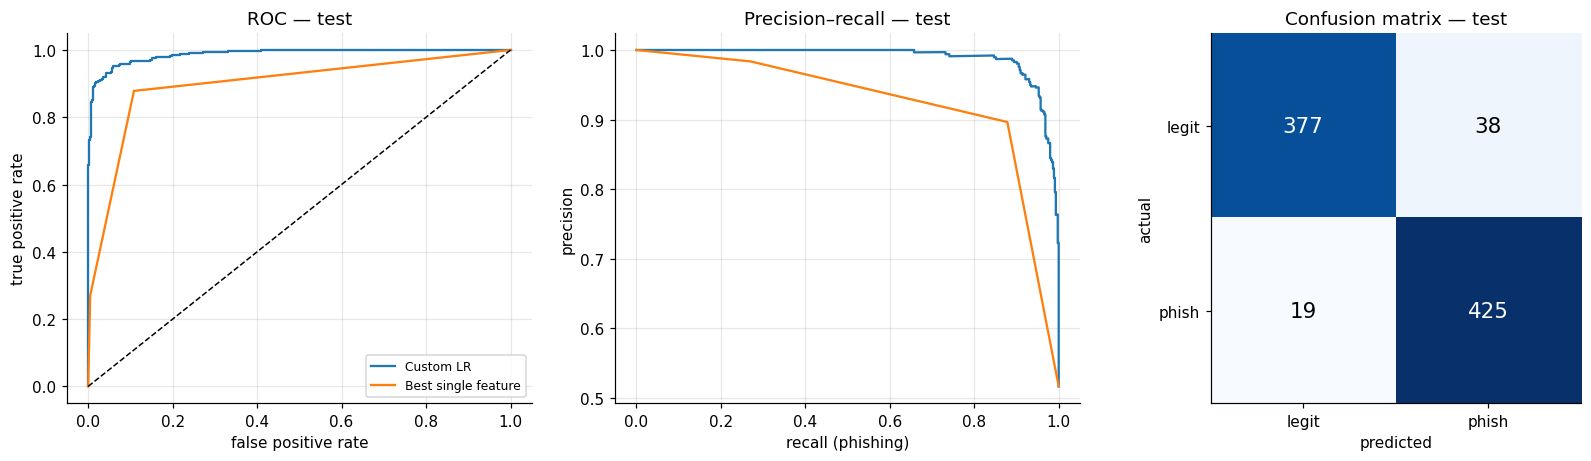

In [19]:
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(15, 4.3))
for name in ("Custom LR", "Best single feature"):
    p = p_test[name][0]
    fpr, tpr, _ = roc_curve(yte, p); prec, rec, _ = precision_recall_curve(yte, p)
    a1.plot(fpr, tpr, label=name); a2.plot(rec, prec, label=name)
a1.plot([0, 1], [0, 1], "k--", lw=1)
a1.set(xlabel="false positive rate", ylabel="true positive rate", title="ROC — test"); a1.legend(fontsize=8)
a2.set(xlabel="recall (phishing)", ylabel="precision", title="Precision–recall — test")
mt = compute_metrics(yte, *p_test["Custom LR"])
cm = np.array([[mt["tn"], mt["fp"]], [mt["fn"], mt["tp"]]])
a3.imshow(cm, cmap="Blues"); a3.grid(False)
for (i, j), v in np.ndenumerate(cm):
    a3.text(j, i, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=14)
a3.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["legit", "phish"], yticklabels=["legit", "phish"],
       xlabel="predicted", ylabel="actual", title="Confusion matrix — test")
plt.tight_layout(); plt.show()

## 7. Overfitting and underfitting

### 7.1 Regularisation strength and encoding

Overfitting shows as a large gap (validation loss ≫ training loss); underfitting as both losses being high.

In [20]:
rows = []
for kind in ("onehot", "raw"):
    Xa, Xb = mats[kind]["train"], mats[kind]["val"]
    Lk = LogisticRegression.smoothness_constant(Xa)
    for l2 in ((0.0, 1e-4, 1e-3, 1e-2, 1e-1) if kind == "onehot" else (0.0, 1e-1)):
        mdl = LogisticRegression(learning_rate=round(1 / Lk, 4), l2=l2, n_iter=30000, tol=1e-9).fit(Xa, ytr)
        rows.append({"encoding": kind, "λ": l2, "‖w‖": np.linalg.norm(mdl.w),
                     "train log-loss": compute_metrics(ytr, mdl.predict_proba(Xa))["log_loss"],
                     "val log-loss": compute_metrics(yva, mdl.predict_proba(Xb))["log_loss"]})
reg = pd.DataFrame(rows)
reg["gap"] = reg["val log-loss"] - reg["train log-loss"]
reg.round(4)

,encoding,λ,‖w‖,train log-loss,val log-loss,gap
0,onehot,0.0000,13.2592,0.1217,0.1393,0.0177
1,onehot,0.0001,11.4411,0.1228,0.1386,0.0157
2,onehot,0.0010,7.5380,0.1371,0.1485,0.0114
3,onehot,0.0100,3.8500,0.2056,0.2117,0.0061
4,onehot,0.1000,1.4085,0.3958,0.3961,0.0003
5,raw,0.0000,5.8902,0.1658,0.1918,0.0260
6,raw,0.1000,1.3526,0.2922,0.2941,0.0019


* **One-hot, small λ:** training and validation loss are close — a good fit.
* **λ = 0.1:** both losses rise together — **under-fitting** from too much regularisation; ‖w‖ shrinks sharply.
* **Raw codes:** worse at every λ — **under-fitting** because a straight line cannot follow non-monotone codes.


### 7.3 Feature selection (selected on training data, scored on validation)

Two transparent methods: a label-free **near-constant filter** (drop a feature whose most common code covers ≥ τ of
training rows) and a supervised **mutual-information ranking** on training labels only (keep the top k).

In [22]:
def near_constant_filter(train_df, features, tau):
    share = train_df[features].apply(lambda c: c.value_counts(normalize=True).max())
    return [f for f in features if share[f] < tau]


def mutual_information_ranking(train_df, features, target):
    """Mutual information (bits) between each feature and the label, highest first."""
    y = train_df[target].to_numpy()
    return pd.Series({f: mutual_info_score(train_df[f].to_numpy(), y) / np.log(2) for f in features}).sort_values(ascending=False)


mi = mutual_information_ranking(train, FEATS, TARGET)
print("near-constant filter τ = 0.95 removes:", sorted(set(FEATS) - set(near_constant_filter(train, FEATS, 0.95))))
print("top 8 by mutual information:", list(mi.index[:8]))


def fit_subset(features):
    e = FeatureEncoder("onehot").fit(train[features + [TARGET]])
    Xa, Xb = e.transform(train), e.transform(val)
    m = LogisticRegression(learning_rate=round(1 / LogisticRegression.smoothness_constant(Xa), 4), l2=SEL["l2"],
                           n_iter=30000, tol=1e-9).fit(Xa, ytr)
    pb = m.predict_proba(Xb)
    return {"features": len(features), "val ROC-AUC": roc_auc_score(yva, pb), "val F1": compute_metrics(yva, pb, tune_threshold(yva, pb))["f1"]}


fs = {f"MI top {k}": fit_subset(list(mi.index[:k])) for k in (3, 8, 15)}
fs["all 30"] = {"features": 30, "val ROC-AUC": roc_auc_score(yva, p_val), "val F1": compute_metrics(yva, p_val, THR)["f1"]}
pd.DataFrame(fs).T.round(4)

near-constant filter τ = 0.95 removes: ['rightclick']
top 8 by mutual information: ['sslfinal_state', 'url_of_anchor', 'prefix_suffix', 'having_sub_domain', 'web_traffic', 'sfh', 'links_in_tags', 'request_url']


,features,val ROC-AUC,val F1
MI top 3,3.0,0.9651,0.9236
MI top 8,8.0,0.9846,0.9469
MI top 15,15.0,0.9867,0.9470
all 30,30.0,0.9881,0.9531


Fewer features mostly simplify the model; no reduced set *improves* accuracy, so the main model keeps all 30. The top 8 are used for the app (Part 9).

## 8. Interpretation

### 8.1 Coefficients

Each one-hot coefficient is the change in log-odds of phishing compared with the reference level (code 1) of the
same feature, holding the others fixed; $e^{\beta}$ is the odds multiplier. Associations, not causes.

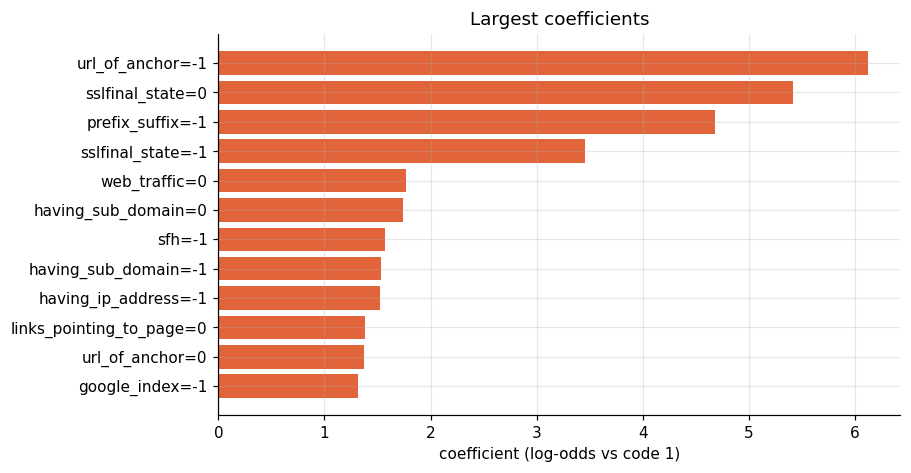

intercept b = -11.68 (strongly negative: the all-legitimate-like profile is almost never phishing)


,coefficient,odds multiplier
url_of_anchor=-1,6.120,454.8
sslfinal_state=0,5.415,224.7
prefix_suffix=-1,4.681,107.9
sslfinal_state=-1,3.459,31.8
web_traffic=0,1.764,5.8
having_sub_domain=0,1.736,5.7


In [23]:
coefs = pd.Series(lr.w, index=enc.output_names)
top_c = coefs.reindex(coefs.abs().sort_values(ascending=False).index)[:12]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top_c.index[::-1], top_c.values[::-1], color=[PHISH if v > 0 else LEGIT for v in top_c.values[::-1]])
ax.axvline(0, color="grey", lw=1); ax.set(xlabel="coefficient (log-odds vs code 1)", title="Largest coefficients")
plt.show()
print(f"intercept b = {lr.b:.2f} (strongly negative: the all-legitimate-like profile is almost never phishing)")
pd.DataFrame({"coefficient": top_c.round(3), "odds multiplier": np.exp(top_c).round(1)}).head(6)

### 8.2 Permutation importance (validation)

Shuffle one original feature (all of its one-hot columns move together) and measure the drop in validation ROC-AUC.
Correlated features share credit.

In [24]:
def permutation_importance(predict, frame, y, features, n_repeats=10, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    base = roc_auc_score(y, predict(frame))
    rows = []
    for f in features:
        drops = []
        for _ in range(n_repeats):
            shuffled = frame.copy()
            shuffled[f] = rng.permutation(shuffled[f].to_numpy())
            drops.append(base - roc_auc_score(y, predict(shuffled)))
        rows.append({"feature": f, "mean ROC-AUC drop": np.mean(drops), "sd": np.std(drops, ddof=1)})
    return pd.DataFrame(rows).sort_values("mean ROC-AUC drop", ascending=False).reset_index(drop=True)


permutation_importance(lambda df: lr.predict_proba(enc.transform(df)), val, yva, FEATS).head(8).round(4)

,feature,mean ROC-AUC drop,sd
0,url_of_anchor,0.0766,0.0096
1,sslfinal_state,0.0547,0.0043
2,prefix_suffix,0.0158,0.0029
3,web_traffic,0.0056,0.0008
4,having_ip_address,0.0041,0.0008
5,sfh,0.0030,0.0012
6,links_in_tags,0.0026,0.0009
7,links_pointing_to_page,0.0024,0.0009


## 9. The app's 8-input model

A 30-question form is too long, so the app uses a separate logistic regression on the **top 8 features by training
mutual information**, trained and tuned with exactly the same rules.

In [25]:
Q_FEATS = list(mi.index[:8])
q_enc = FeatureEncoder("onehot").fit(train[Q_FEATS + [TARGET]])
qXtr, qXva, qXte = (q_enc.transform(d) for d in (train, val, test))
# Same selection rule as Part 5 (lowest validation log-loss to 4 decimals; ties -> smaller step), over the three
# step sizes at the selected λ.
qL = LogisticRegression.smoothness_constant(qXtr)
cands = []
for frac in (0.5, 1.0, 1.9):
    m = LogisticRegression(learning_rate=round(frac / qL, 4), l2=SEL["l2"], n_iter=30000, tol=1e-9).fit(qXtr, ytr)
    cands.append((round(compute_metrics(yva, m.predict_proba(qXva))["log_loss"], 4), m.learning_rate, m))
    print(f"step {frac}/L = {m.learning_rate}: validation log-loss {cands[-1][0]}, {m.n_iter_run:,} iterations")
q_lr = min(cands, key=lambda c: (c[0], c[1]))[2]
q_pva, q_pte = q_lr.predict_proba(qXva), q_lr.predict_proba(qXte)
Q_THR = tune_threshold(yva, q_pva)
print(f"selected step {q_lr.learning_rate} · {len(Q_FEATS)} features -> {qXtr.shape[1]} one-hot inputs · threshold {Q_THR:.2f}")
d = paired_bootstrap_diff(yte, q_pte, Q_THR, *p_test["Custom LR"])
print(f"8 vs 30 inputs on test: ΔF1 {d['f1']['mean']:+.3f} [{d['f1']['low']:+.3f}, {d['f1']['high']:+.3f}] → {verdict(d['f1'])}")
pd.DataFrame({"8 inputs (app)": metrics_row(yte, q_pte, Q_THR), "30 inputs": metrics_row(yte, *p_test["Custom LR"])}).T

step 0.5/L = 0.5272: validation log-loss 0.1623, 23,325 iterations


step 1.0/L = 1.0544: validation log-loss 0.1623, 12,996 iterations


step 1.9/L = 2.0033: validation log-loss 0.1623, 7,499 iterations


selected step 0.5272 · 8 features -> 14 one-hot inputs · threshold 0.28


8 vs 30 inputs on test: ΔF1 -0.005 [-0.019, +0.006] → small or uncertain difference


,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
8 inputs (app),0.28,0.927,0.896,0.971,0.932,0.987,0.988
30 inputs,0.35,0.934,0.918,0.957,0.937,0.988,0.989


### 9.1 Three-level verdict: Safe / Suspicious / Likely phishing

Two cut-offs, chosen on **validation only** with a 98% target:

* **low** = the largest threshold that still catches ≥ 98% of phishing sites (≤ 2% of phishing sites are called *Safe*);
* **high** = the smallest threshold at which ≥ 98% of flagged sites are phishing.

In [26]:
ZONES = ("Safe", "Suspicious", "Likely phishing")


def zone_thresholds(y, proba, target=0.98) -> dict:
    grid = np.round(np.arange(0.01, 1.0, 0.01), 2)
    rec = np.array([compute_metrics(y, proba, t)["recall"] for t in grid])
    prec = np.array([compute_metrics(y, proba, t)["precision"] if (proba >= t).any() else 0.0 for t in grid])
    low = float(grid[rec >= target].max())
    return {"low": low, "high": float(max(grid[prec >= target].min(), low)), "target": target}


def assign_zone(proba, low, high) -> np.ndarray:
    p = np.asarray(proba, dtype=float)
    return np.where(p >= high, 2, np.where(p >= low, 1, 0))


Z = zone_thresholds(yva, q_pva)
print("cut-offs:", Z)
zt = assign_zone(q_pte, Z["low"], Z["high"])
pd.DataFrame([{"zone": name, "sites": int((zt == i).sum()), "share": f"{(zt == i).mean():.1%}",
               "phishing rate": f"{yte[zt == i].mean():.1%}"} for i, name in enumerate(ZONES)])

cut-offs: {'low': 0.17, 'high': 0.92, 'target': 0.98}


,zone,sites,share,phishing rate
0,Safe,337,39.2%,2.1%
1,Suspicious,162,18.9%,50.0%
2,Likely phishing,360,41.9%,98.9%


### 9.2 "Why this result?" — each answer's push on the score

For answer $f$, the contribution is $\sum_j w_j (x_j - \bar x_j)$ over its one-hot columns, with $\bar x_j$ the training
average. The contributions add up exactly to the site's log-odds minus that of an average training site, so they say
what moved this site away from "average". (Plain $w_j x_j$ would be 0 for every legitimate-like answer, because that
answer is the reference level.)

phishing probability 96.1% → Likely phishing
check: bars + baseline = 3.1953 | log-odds = 3.1953
Main reason: the site has no valid HTTPS certificate


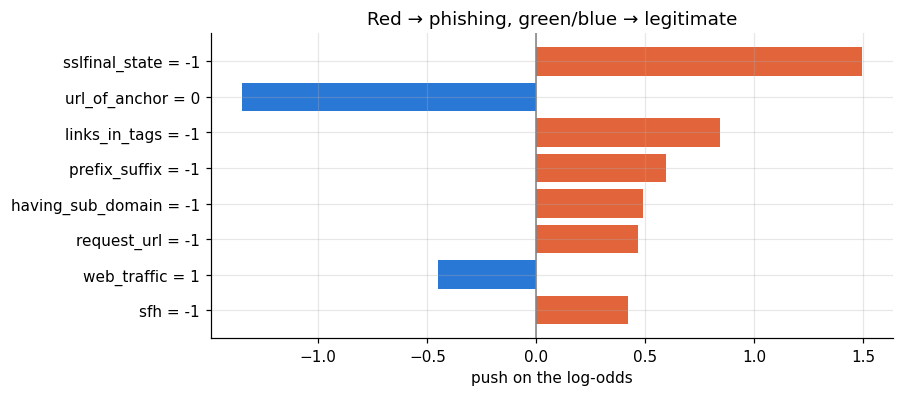

In [ ]:
def contributions(answers: dict) -> pd.Series:
    x = q_enc.transform(pd.DataFrame([answers]))[0]
    per_col = q_lr.w * (x - X_MEAN)
    owner = [n.split("=")[0] for n in q_enc.output_names]
    c = pd.Series(per_col).groupby(owner).sum().reindex(Q_FEATS).fillna(0.0)
    return c.reindex(c.abs().sort_values(ascending=False).index)


example = val[val[TARGET] == 1].iloc[3]
answers = {f: int(example[f]) for f in Q_FEATS}
p = float(q_lr.predict_proba(q_enc.transform(pd.DataFrame([answers])))[0])
c = contributions(answers)
side = c[c > 0] if p >= Q_THR else c[c < 0]
top_f = (side if len(side) else c).abs().idxmax()
print(f"phishing probability {p:.1%} → {ZONES[int(assign_zone([p], Z['low'], Z['high'])[0])]}")
print("check: bars + baseline =", round(c.sum() + BASELINE_LOGIT, 4), "| log-odds =", round(np.log(p / (1 - p)), 4))
print("Main reason:", REASONS[top_f][answers[top_f]])
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh([f"{f} = {answers[f]}" for f in c.index][::-1], c.values[::-1], color=[PHISH if v > 0 else LEGIT for v in c.values[::-1]])
ax.axvline(0, color="grey", lw=1); ax.set(xlabel="push on the log-odds", title="Red → phishing, green/blue → legitimate")
plt.show()

## 10. Verification against the saved models

The pipeline (`python -m src.train`) saved its models to `models/`. If the notebook's own implementation is the
same algorithm with the same data, split and settings, its predictions must be identical.

In [28]:
saved = json.loads((MODELS_DIR / "logistic_regression.json").read_text(encoding="utf-8"))
saved_q = json.loads((MODELS_DIR / "quick_logistic_regression.json").read_text(encoding="utf-8"))
m_saved, q_saved = LogisticRegression.from_dict(saved), LogisticRegression.from_dict(saved_q)
pd.DataFrame({
    "30-input model": {"same input columns": saved["input_names"] == enc.output_names,
                       "max |Δ probability| on test": float(np.abs(m_saved.predict_proba(Xte) - lr.predict_proba(Xte)).max()),
                       "threshold (saved / notebook)": f"{saved['threshold']} / {THR}"},
    "8-input app model": {"same input columns": saved_q["encoder"]["output_names"] == q_enc.output_names,
                          "max |Δ probability| on test": float(np.abs(q_saved.predict_proba(qXte) - q_pte).max()),
                          "threshold (saved / notebook)": f"{saved_q['threshold']} / {Q_THR}"},
})

,30-input model,8-input app model
same input columns,True,True
max |Δ probability| on test,0.0,0.0
threshold (saved / notebook),0.35 / 0.35,0.28 / 0.28


In [29]:
# Save / load round trip with the notebook's own class.
again = LogisticRegression.from_dict(json.loads(json.dumps(lr.to_dict())))
print("identical after save → load:", np.array_equal(again.predict_proba(Xte), lr.predict_proba(Xte)))

identical after save → load: True


## 11. Conclusion

* Almost half of the raw rows were duplicates; cleaning **before** splitting keeps the test honest.
* The from-scratch **Logistic Regression** reaches test F1 ≈ 0.937 and ROC-AUC ≈ 0.988 — a clear improvement over the
  best single-feature baseline — and matches scikit-learn's reference trained on the same objective.
* One-hot encoding fixes the non-monotone codes; L2 strength, encoding and step size were all chosen on validation
  data, and the model neither over- nor under-fits at the selected setting.
* **HTTPS certificate status** and **anchor-link targets** carry most of the signal.
* The app's 8-input model has no measurable loss against all 30 inputs, with a form that is 73% shorter.

**Limitations.** The data date from about 2012, some inputs depend on retired services (Alexa rank, public PageRank),
the evaluation uses unique feature vectors rather than real traffic, features must be pre-extracted, and a linear
model cannot learn feature interactions on its own.